In [ ]:
!pip -q install transformers tokenizers datasets accelerate pandas numpy scikit-learn matplotlib

In [ ]:
import torch

print("=" * 50)
print("ENVIRONMENT VERIFICATION")
print("=" * 50)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):", round(
        torch.cuda.get_device_properties(0).total_memory / (1024**3), 2
    ))
    print("Device selected: CUDA")
else:
    print("Device selected: CPU")
    print("WARNING: Enable a GPU in Colab for model training.")

print("\nEnvironment verification completed!")


ENVIRONMENT VERIFICATION
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU name: Tesla T4
GPU memory (GB): 14.56
Device selected: CUDA

Environment verification completed!


In [ ]:
import os
import gc
import json
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split

from tokenizers import BertWordPieceTokenizer

from transformers import (
    BertConfig,
    BertForMaskedLM,
    BertTokenizerFast,
    DataCollatorForLanguageModeling,
    get_linear_schedule_with_warmup
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 55)
print("LIBRARY IMPORTS COMPLETED")
print("=" * 55)
print("PyTorch:", torch.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Random seed:", SEED)
print("All libraries imported successfully!")


LIBRARY IMPORTS COMPLETED
PyTorch: 2.11.0+cu130
Pandas: 2.2.3
NumPy: 2.1.3
Device: cuda
GPU: Tesla T4
Random seed: 42
All libraries imported successfully!


In [ ]:

DATA_URL = "https://huggingface.co/datasets/aitetic/arxiv-cs/resolve/main/arxiv-cs-2015-2024.jsonl"

print("=" * 55)
print("LOADING ARXIV CS DATASET")
print("=" * 55)
print("Dataset URL:", DATA_URL)

df = pd.read_json(DATA_URL, lines=True)

print("\nDataset loaded successfully!")
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))
print("Column names:", df.columns.tolist())

print("\nFirst 3 rows:")
display(df.head(3))


LOADING ARXIV CS DATASET
Dataset URL: https://huggingface.co/datasets/aitetic/arxiv-cs/resolve/main/arxiv-cs-2015-2024.jsonl

Dataset loaded successfully!
Number of rows: 1432025
Number of columns: 5
Column names: ['title', 'description', 'date', 'terms', 'ref']

First 3 rows:


,title,description,date,terms,ref
0,A Kochen-Specker system has at least 22 vector...,At the heart of the Conway-Kochen Free Will th...,2015-01-01,cs.DM,1412.8544
1,A Kochen-Specker system has at least 22 vector...,At the heart of the Conway-Kochen Free Will th...,2015-01-02,cs.DM,1412.8544
2,Managing key multicasting through orthogonal s...,In this paper we propose a new protocol to man...,2015-01-04,cs.CR,1107.0586


In [ ]:

print("=" * 60)
print("DATASET STRUCTURE EXPLORATION")
print("=" * 60)

print("\n1. Dataset dimensions:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\n2. Column names:")
print(df.columns.tolist())

print("\n3. Data types:")
print(df.dtypes)

print("\n4. Dataset information:")
df.info()

print("\n5. First 5 records:")
display(df.head())

print("\n6. Random 5 records:")
display(df.sample(n=5, random_state=42))

print("\n7. Unique values in selected columns:")
for column in ["date", "terms", "ref"]:
    print(f"{column}: {df[column].nunique(dropna=True)} unique values")

print("\nDataset exploration completed successfully!")


DATASET STRUCTURE EXPLORATION

1. Dataset dimensions:
Rows: 1432025
Columns: 5

2. Column names:
['title', 'description', 'date', 'terms', 'ref']

3. Data types:
title                  object
description            object
date           datetime64[ns]
terms                  object
ref                    object
dtype: object

4. Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1432025 entries, 0 to 1432024
Data columns (total 5 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   title        1432025 non-null  object        
 1   description  1432025 non-null  object        
 2   date         1432025 non-null  datetime64[ns]
 3   terms        1432025 non-null  object        
 4   ref          1432025 non-null  object        
dtypes: datetime64[ns](1), object(4)
memory usage: 54.6+ MB

5. First 5 records:


,title,description,date,terms,ref
0,A Kochen-Specker system has at least 22 vector...,At the heart of the Conway-Kochen Free Will th...,2015-01-01,cs.DM,1412.8544
1,A Kochen-Specker system has at least 22 vector...,At the heart of the Conway-Kochen Free Will th...,2015-01-02,cs.DM,1412.8544
2,Managing key multicasting through orthogonal s...,In this paper we propose a new protocol to man...,2015-01-04,cs.CR,1107.0586
3,Channel Capacity under Sub-Nyquist Nonuniform ...,This paper investigates the effect of sub-Nyqu...,2015-01-04,cs.IT math.IT,1204.6049
4,On bounding the bandwidth of graphs with symmetry,We derive a new lower bound for the bandwidth ...,2015-01-04,math.OC cs.DM math.CO,1212.0694



6. Random 5 records:


,title,description,date,terms,ref
688749,Domain-specific Language Pre-training for Dial...,There is growing interest in the automated ext...,2022-06-06,cs.CL,2206.02428
144913,Scalable Generalized Linear Bandits: Online Co...,"Generalized Linear Bandits (GLBs), a natural e...",2017-10-24,stat.ML cs.LG,1706.00136
1131777,Network Degeneracy as an Indicator of Training...,Neural networks are powerful functions with wi...,2024-08-15,cs.LG stat.ML,2306.01513
674450,What Factors Should Paper-Reviewer Assignments...,Both scientific progress and individual resear...,2022-05-04,cs.CL,2205.01005
521137,LatentSLAM: unsupervised multi-sensor represen...,Biologically inspired algorithms for simultane...,2021-05-09,cs.RO cs.AI,2105.03265



7. Unique values in selected columns:
date: 3442 unique values
terms: 40407 unique values
ref: 716377 unique values

Dataset exploration completed successfully!


In [ ]:
print("=" * 60)
print("MISSING VALUES AND DUPLICATE ANALYSIS")
print("=" * 60)

print("\n1. Missing values per column:")
print(df.isnull().sum())

print("\n2. Missing values percentage:")
missing_percent = (df.isnull().sum() / len(df)) * 100
print(missing_percent.round(4))

print("\n3. Number of fully duplicated rows:")
print(df.duplicated().sum())

print("\n4. Duplicate references:")
print("Total rows:", len(df))
print("Unique references:", df["ref"].nunique())
print("Rows beyond unique reference count:",
      len(df) - df["ref"].nunique())

print("\n5. Duplicate titles:")
print("Unique titles:", df["title"].nunique())
print("Rows beyond unique title count:",
      len(df) - df["title"].nunique())

print("\n6. Duplicate descriptions:")
print("Unique descriptions:", df["description"].nunique())
print("Rows beyond unique description count:",
      len(df) - df["description"].nunique())

print("\nMissing values and duplicate analysis completed!")


MISSING VALUES AND DUPLICATE ANALYSIS

1. Missing values per column:
title          0
description    0
date           0
terms          0
ref            0
dtype: int64

2. Missing values percentage:
title          0.0
description    0.0
date           0.0
terms          0.0
ref            0.0
dtype: float64

3. Number of fully duplicated rows:
0

4. Duplicate references:
Total rows: 1432025
Unique references: 716377
Rows beyond unique reference count: 715648

5. Duplicate titles:
Unique titles: 715962
Rows beyond unique title count: 716063

6. Duplicate descriptions:
Unique descriptions: 716188
Rows beyond unique description count: 715837

Missing values and duplicate analysis completed!


In [ ]:

print("=" * 60)
print("TEXT EXTRACTION AND CLEANING")
print("=" * 60)

corpus = df[["title", "description", "ref", "date", "terms"]].copy()

corpus["title"] = (
    corpus["title"]
    .fillna("")
    .astype(str)
    .str.strip()
)

corpus["description"] = (
    corpus["description"]
    .fillna("")
    .astype(str)
    .str.strip()
)

corpus["text"] = (
    corpus["title"] + ". " + corpus["description"]
).str.replace(r"\s+", " ", regex=True).str.strip()

print("Original number of rows:", len(df))
print("Number of extracted documents:", len(corpus))

print("\nText length statistics:")
print(corpus["text"].str.len().describe())

print("\nExample of an extracted document:")
print(corpus["text"].iloc[0][:1000])

print("\nText extraction and cleaning completed!")


TEXT EXTRACTION AND CLEANING
Original number of rows: 1432025
Number of extracted documents: 1432025

Text length statistics:
count    1.432025e+06
mean     1.254624e+03
std      3.651130e+02
min      5.300000e+01
25%      1.006000e+03
50%      1.251000e+03
75%      1.507000e+03
max      4.153000e+03
Name: text, dtype: float64

Example of an extracted document:
A Kochen-Specker system has at least 22 vectors (extended abstract). At the heart of the Conway-Kochen Free Will theorem and Kochen and Specker's argument against non-contextual hidden variable theories is the existence of a Kochen-Specker (KS) system: a set of points on the sphere that has no 0,1-coloring such that at most one of two orthogonal points are colored 1 and of three pairwise orthogonal points exactly one is colored 1. In public lectures, Conway encouraged the search for small KS systems. At the time of writing, the smallest known KS system has 31 vectors. Arends, Ouaknine and Wampler have shown that a KS system has 

In [ ]:
print("=" * 60)
print("FILTERING, DEDUPLICATION AND 300K SELECTION")
print("=" * 60)

# Remove empty documents
corpus = corpus[corpus["text"].str.len() > 0].copy()

print("Documents after removing empty texts:", len(corpus))


corpus = corpus.drop_duplicates(subset=["text"], keep="first")
corpus = corpus.reset_index(drop=True)

print("Unique documents after deduplication:", len(corpus))


TARGET_DOCUMENTS = 300_000

if len(corpus) < TARGET_DOCUMENTS:
    raise ValueError(
        f"Only {len(corpus)} unique documents are available; "
        f"{TARGET_DOCUMENTS} are required."
    )

corpus = corpus.head(TARGET_DOCUMENTS).reset_index(drop=True)

print("\nFinal corpus selection:")
print("Number of documents:", len(corpus))
print("Unique texts:", corpus["text"].nunique())
print("Selection method: first 300,000 unique documents in dataset order")

assert len(corpus) == 300_000
assert corpus["text"].nunique() == 300_000

print("\nExactly 300,000 unique documents selected successfully!")


FILTERING, DEDUPLICATION AND 300K SELECTION
Documents after removing empty texts: 1432025
Unique documents after deduplication: 716305

Final corpus selection:
Number of documents: 300000
Unique texts: 300000
Selection method: first 300,000 unique documents in dataset order

Exactly 300,000 unique documents selected successfully!


In [ ]:
print("=" * 60)
print("TRAIN / VALIDATION / TEST SPLIT")
print("=" * 60)

# First split: 80% training and 20% temporary data
train_df, temp_df = train_test_split(
    corpus,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    shuffle=True
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train documents:", len(train_df))
print("Validation documents:", len(val_df))
print("Test documents:", len(test_df))
print("Total documents:", len(train_df) + len(val_df) + len(test_df))

print("\nSplit percentages:")
print(f"Train: {len(train_df) / len(corpus) * 100:.1f}%")
print(f"Validation: {len(val_df) / len(corpus) * 100:.1f}%")
print(f"Test: {len(test_df) / len(corpus) * 100:.1f}%")

assert len(train_df) == 240_000
assert len(val_df) == 30_000
assert len(test_df) == 30_000

train_texts = set(train_df["text"])
val_texts = set(val_df["text"])
test_texts = set(test_df["text"])

assert train_texts.isdisjoint(val_texts)
assert train_texts.isdisjoint(test_texts)
assert val_texts.isdisjoint(test_texts)

print("\nAll split checks passed!")


TRAIN / VALIDATION / TEST SPLIT
Train documents: 240000
Validation documents: 30000
Test documents: 30000
Total documents: 300000

Split percentages:
Train: 80.0%
Validation: 10.0%
Test: 10.0%

All split checks passed!


DESCRIPTIVE ANALYSIS OF THE 300K CORPUS

1. Dataset sizes:
Train: 240,000
Validation: 30,000
Test: 30,000

2. Text length statistics (characters):

Train:
  Mean: 1176.94
  Median: 1163.00
  Minimum: 53
  Maximum: 3988

Validation:
  Mean: 1181.23
  Median: 1169.00
  Minimum: 90
  Maximum: 3139

Test:
  Mean: 1175.09
  Median: 1161.00
  Minimum: 71
  Maximum: 2935


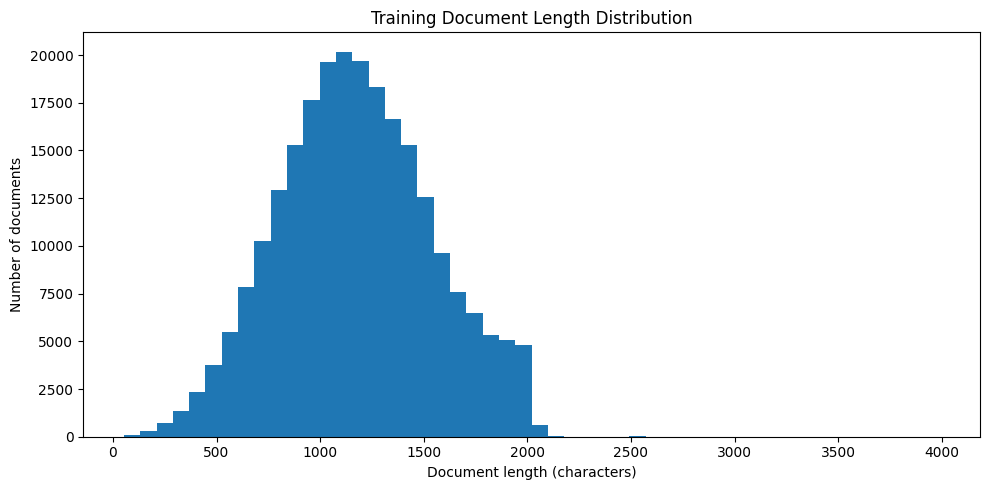


3. Sample training documents:

Document 1:
Towards Resilience for Multi-Agent $QD$-Learning. This paper considers the multi-agent reinforcement learning (MARL) problem for a networked (peer-to-peer) system in the presence of Byzantine agents. We build on an existing distributed $Q$-learning algorithm, and allow certain agents in the network to behave in an arbitrary and adversarial manner (as captured by the Byzantine attack model). Under the proposed algorithm, if the network topology is $(2F+1)$-robust and up to $F$ Byzantine agents ex

Document 2:
Near-Optimal Closeness Testing of Discrete Histogram Distributions. We investigate the problem of testing the equivalence between two discrete histograms. A {\em $k$-histogram} over $[n]$ is a probability distribution that is piecewise constant over some set of $k$ intervals over $[n]$. Histograms have been extensively studied in computer science and statistics. Given a set of samples from two $k$-histogram distributions $p, q$ over $[n]$

In [ ]:
print("=" * 60)
print("DESCRIPTIVE ANALYSIS OF THE 300K CORPUS")
print("=" * 60)

print("\n1. Dataset sizes:")
print(f"Train: {len(train_df):,}")
print(f"Validation: {len(val_df):,}")
print(f"Test: {len(test_df):,}")

print("\n2. Text length statistics (characters):")
for name, split_df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    lengths = split_df["text"].str.len()
    print(f"\n{name}:")
    print(f"  Mean: {lengths.mean():.2f}")
    print(f"  Median: {lengths.median():.2f}")
    print(f"  Minimum: {lengths.min()}")
    print(f"  Maximum: {lengths.max()}")

plt.figure(figsize=(10, 5))
plt.hist(train_df["text"].str.len(), bins=50)
plt.title("Training Document Length Distribution")
plt.xlabel("Document length (characters)")
plt.ylabel("Number of documents")
plt.tight_layout()
plt.show()

print("\n3. Sample training documents:")
for i in range(3):
    print(f"\nDocument {i + 1}:")
    print(train_df.loc[i, "text"][:500])

print("\nCorpus descriptive analysis completed successfully!")

In [ ]:
import os

PROJECT_DIR = "/kaggle/working/minimal_token_sets_300k"
TOKENIZER_DIR = os.path.join(PROJECT_DIR, "tokenizers")
os.makedirs(TOKENIZER_DIR, exist_ok=True)

VOCAB_SIZES = [8_000, 16_000, 32_000]

SPECIAL_TOKENS = [
    "[PAD]",
    "[UNK]",
    "[CLS]",
    "[SEP]",
    "[MASK]"
]

MIN_FREQUENCY = 2
LOWERCASE = False
STRIP_ACCENTS = False

print("=" * 60)
print("WORDPIECE TOKENIZER CONFIGURATION")
print("=" * 60)

print("Vocabulary sizes:", VOCAB_SIZES)
print("Special tokens:", SPECIAL_TOKENS)
print("Minimum token frequency:", MIN_FREQUENCY)
print("Lowercase:", LOWERCASE)
print("Strip accents:", STRIP_ACCENTS)
print("Tokenizer output directory:", TOKENIZER_DIR)
print("Directory exists:", os.path.isdir(TOKENIZER_DIR))

if "train_df" in globals():
    print("Training documents:", len(train_df))
else:
    print("WARNING: train_df is not available in memory.")

print("\nWordPiece configuration completed!")


WORDPIECE TOKENIZER CONFIGURATION
Vocabulary sizes: [8000, 16000, 32000]
Special tokens: ['[PAD]', '[UNK]', '[CLS]', '[SEP]', '[MASK]']
Minimum token frequency: 2
Lowercase: False
Strip accents: False
Tokenizer output directory: /kaggle/working/minimal_token_sets_300k/tokenizers
Directory exists: True
Training documents: 240000

WordPiece configuration completed!


In [ ]:
import os
import time
from tokenizers import BertWordPieceTokenizer

print("=" * 60)
print("TRAINING WORDPIECE TOKENIZER 8K")
print("=" * 60)

vocab_size = 8_000
output_dir = os.path.join(TOKENIZER_DIR, "wordpiece_8000")
os.makedirs(output_dir, exist_ok=True)

tokenizer_8k = BertWordPieceTokenizer(
    lowercase=LOWERCASE,
    strip_accents=STRIP_ACCENTS,
    clean_text=True,
    handle_chinese_chars=True
)

start_time = time.time()

tokenizer_8k.train_from_iterator(
    iterator=train_df["text"].astype(str),
    vocab_size=vocab_size,
    min_frequency=MIN_FREQUENCY,
    special_tokens=SPECIAL_TOKENS,
    show_progress=True
)

tokenizer_8k.save_model(output_dir)
tokenizer_8k.save(os.path.join(output_dir, "tokenizer.json"))

elapsed_time = time.time() - start_time
actual_vocab_size = tokenizer_8k.get_vocab_size()

print("\n" + "=" * 60)
print("WORDPIECE 8K TRAINING COMPLETED")
print("=" * 60)
print("Target vocabulary size:", vocab_size)
print("Actual vocabulary size:", actual_vocab_size)
print("PAD token ID:", tokenizer_8k.token_to_id("[PAD]"))
print("UNK token ID:", tokenizer_8k.token_to_id("[UNK]"))
print("CLS token ID:", tokenizer_8k.token_to_id("[CLS]"))
print("SEP token ID:", tokenizer_8k.token_to_id("[SEP]"))
print("MASK token ID:", tokenizer_8k.token_to_id("[MASK]"))
print("Training time (seconds):", round(elapsed_time, 2))
print("Saved directory:", output_dir)

assert actual_vocab_size == vocab_size
assert all(tokenizer_8k.token_to_id(t) is not None for t in SPECIAL_TOKENS)

print("\nTokenizer 8K saved and verified successfully!")


TRAINING WORDPIECE TOKENIZER 8K

WORDPIECE 8K TRAINING COMPLETED
Target vocabulary size: 8000
Actual vocabulary size: 8000
PAD token ID: 0
UNK token ID: 1
CLS token ID: 2
SEP token ID: 3
MASK token ID: 4
Training time (seconds): 71.4
Saved directory: /kaggle/working/minimal_token_sets_300k/tokenizers/wordpiece_8000

Tokenizer 8K saved and verified successfully!


In [ ]:
import os
import time
from tokenizers import BertWordPieceTokenizer

print("=" * 60)
print("TRAINING WORDPIECE TOKENIZER 16K")
print("=" * 60)

vocab_size = 16_000
output_dir = os.path.join(TOKENIZER_DIR, "wordpiece_16000")
os.makedirs(output_dir, exist_ok=True)

tokenizer_16k = BertWordPieceTokenizer(
    lowercase=LOWERCASE,
    strip_accents=STRIP_ACCENTS,
    clean_text=True,
    handle_chinese_chars=True
)

start_time = time.time()

tokenizer_16k.train_from_iterator(
    iterator=train_df["text"].astype(str),
    vocab_size=vocab_size,
    min_frequency=MIN_FREQUENCY,
    special_tokens=SPECIAL_TOKENS,
    show_progress=True
)

tokenizer_16k.save_model(output_dir)
tokenizer_16k.save(os.path.join(output_dir, "tokenizer.json"))

elapsed_time = time.time() - start_time
actual_vocab_size = tokenizer_16k.get_vocab_size()

print("\n" + "=" * 60)
print("WORDPIECE 16K TRAINING COMPLETED")
print("=" * 60)
print("Target vocabulary size:", vocab_size)
print("Actual vocabulary size:", actual_vocab_size)
print("PAD token ID:", tokenizer_16k.token_to_id("[PAD]"))
print("UNK token ID:", tokenizer_16k.token_to_id("[UNK]"))
print("CLS token ID:", tokenizer_16k.token_to_id("[CLS]"))
print("SEP token ID:", tokenizer_16k.token_to_id("[SEP]"))
print("MASK token ID:", tokenizer_16k.token_to_id("[MASK]"))
print("Training time (seconds):", round(elapsed_time, 2))
print("Saved directory:", output_dir)

assert actual_vocab_size == vocab_size
assert all(tokenizer_16k.token_to_id(t) is not None for t in SPECIAL_TOKENS)

print("\nTokenizer 16K saved and verified successfully!")


TRAINING WORDPIECE TOKENIZER 16K

WORDPIECE 16K TRAINING COMPLETED
Target vocabulary size: 16000
Actual vocabulary size: 16000
PAD token ID: 0
UNK token ID: 1
CLS token ID: 2
SEP token ID: 3
MASK token ID: 4
Training time (seconds): 71.4
Saved directory: /kaggle/working/minimal_token_sets_300k/tokenizers/wordpiece_16000

Tokenizer 16K saved and verified successfully!


In [ ]:
import os
import time
from tokenizers import BertWordPieceTokenizer

print("=" * 60)
print("TRAINING WORDPIECE TOKENIZER 32K")
print("=" * 60)

vocab_size = 32_000
output_dir = os.path.join(TOKENIZER_DIR, "wordpiece_32000")
os.makedirs(output_dir, exist_ok=True)

tokenizer_32k = BertWordPieceTokenizer(
    lowercase=LOWERCASE,
    strip_accents=STRIP_ACCENTS,
    clean_text=True,
    handle_chinese_chars=True
)

start_time = time.time()

tokenizer_32k.train_from_iterator(
    iterator=train_df["text"].astype(str),
    vocab_size=vocab_size,
    min_frequency=MIN_FREQUENCY,
    special_tokens=SPECIAL_TOKENS,
    show_progress=True
)

tokenizer_32k.save_model(output_dir)
tokenizer_32k.save(os.path.join(output_dir, "tokenizer.json"))

elapsed_time = time.time() - start_time
actual_vocab_size = tokenizer_32k.get_vocab_size()

print("\n" + "=" * 60)
print("WORDPIECE 32K TRAINING COMPLETED")
print("=" * 60)
print("Target vocabulary size:", vocab_size)
print("Actual vocabulary size:", actual_vocab_size)
print("PAD token ID:", tokenizer_32k.token_to_id("[PAD]"))
print("UNK token ID:", tokenizer_32k.token_to_id("[UNK]"))
print("CLS token ID:", tokenizer_32k.token_to_id("[CLS]"))
print("SEP token ID:", tokenizer_32k.token_to_id("[SEP]"))
print("MASK token ID:", tokenizer_32k.token_to_id("[MASK]"))
print("Training time (seconds):", round(elapsed_time, 2))
print("Saved directory:", output_dir)

assert actual_vocab_size == vocab_size
assert all(tokenizer_32k.token_to_id(t) is not None for t in SPECIAL_TOKENS)

print("\nTokenizer 32K saved and verified successfully!")


TRAINING WORDPIECE TOKENIZER 32K

WORDPIECE 32K TRAINING COMPLETED
Target vocabulary size: 32000
Actual vocabulary size: 32000
PAD token ID: 0
UNK token ID: 1
CLS token ID: 2
SEP token ID: 3
MASK token ID: 4
Training time (seconds): 71.92
Saved directory: /kaggle/working/minimal_token_sets_300k/tokenizers/wordpiece_32000

Tokenizer 32K saved and verified successfully!


In [ ]:
import os
import pandas as pd
from tokenizers import BertWordPieceTokenizer

print("=" * 65)
print("WORDPIECE VOCABULARY AND SPECIAL TOKEN VERIFICATION")
print("=" * 65)

vocab_sizes = [8_000, 16_000, 32_000]
results = []

for size in vocab_sizes:
    tokenizer_dir = os.path.join(
        TOKENIZER_DIR, f"wordpiece_{size}"
    )
    vocab_path = os.path.join(tokenizer_dir, "vocab.txt")
    tokenizer_json_path = os.path.join(tokenizer_dir, "tokenizer.json")

    tokenizer = BertWordPieceTokenizer(
        vocab_path,
        lowercase=LOWERCASE,
        strip_accents=STRIP_ACCENTS
    )

    actual_size = tokenizer.get_vocab_size()

    results.append({
        "Target vocabulary": size,
        "Actual vocabulary": actual_size,
        "PAD ID": tokenizer.token_to_id("[PAD]"),
        "UNK ID": tokenizer.token_to_id("[UNK]"),
        "CLS ID": tokenizer.token_to_id("[CLS]"),
        "SEP ID": tokenizer.token_to_id("[SEP]"),
        "MASK ID": tokenizer.token_to_id("[MASK]"),
        "vocab.txt exists": os.path.isfile(vocab_path),
        "tokenizer.json exists": os.path.isfile(tokenizer_json_path)
    })

    assert actual_size == size
    assert all(
        tokenizer.token_to_id(token) == index
        for index, token in enumerate(SPECIAL_TOKENS)
    )
    assert os.path.isfile(vocab_path)
    assert os.path.isfile(tokenizer_json_path)

results_df = pd.DataFrame(results)

display(results_df)

print("\nAll vocabulary sizes and special token IDs verified!")


WORDPIECE VOCABULARY AND SPECIAL TOKEN VERIFICATION


,Target vocabulary,Actual vocabulary,PAD ID,UNK ID,CLS ID,SEP ID,MASK ID,vocab.txt exists,tokenizer.json exists
0,8000,8000,0,1,2,3,4,True,True
1,16000,16000,0,1,2,3,4,True,True
2,32000,32000,0,1,2,3,4,True,True



All vocabulary sizes and special token IDs verified!


In [ ]:
import os
import json
from datetime import datetime

print("=" * 60)
print("SAVING WORDPIECE TOKENIZER CONFIGURATION")
print("=" * 60)

tokenizer_summary = {
    "project": "Minimal Token Sets for LLMs: Quantifying the Learning Space",
    "tokenizer_type": "WordPiece",
    "training_documents": 240000,
    "vocabulary_sizes": [8000, 16000, 32000],
    "special_tokens": SPECIAL_TOKENS,
    "special_token_ids": {
        token: index for index, token in enumerate(SPECIAL_TOKENS)
    },
    "min_frequency": MIN_FREQUENCY,
    "lowercase": LOWERCASE,
    "strip_accents": STRIP_ACCENTS,
    "random_seed": SEED,
    "created_at": datetime.now().isoformat(timespec="seconds")
}

summary_path = os.path.join(
    TOKENIZER_DIR, "tokenizer_experiment_config.json"
)

with open(summary_path, "w", encoding="utf-8") as file:
    json.dump(tokenizer_summary, file, indent=4, ensure_ascii=False)

print("Configuration saved:", summary_path)

print("\nTokenizer files:")
for size in VOCAB_SIZES:
    tokenizer_dir = os.path.join(
        TOKENIZER_DIR, f"wordpiece_{size}"
    )
    print(f"\nWordPiece {size // 1000}K:")
    for filename in ["vocab.txt", "tokenizer.json"]:
        path = os.path.join(tokenizer_dir, filename)
        print(f"  {filename}: {'OK' if os.path.isfile(path) else 'MISSING'}")

print("\nConfiguration file exists:", os.path.isfile(summary_path))
print("Tokenizer configuration saved successfully!")


SAVING WORDPIECE TOKENIZER CONFIGURATION
Configuration saved: /kaggle/working/minimal_token_sets_300k/tokenizers/tokenizer_experiment_config.json

Tokenizer files:

WordPiece 8K:
  vocab.txt: OK
  tokenizer.json: OK

WordPiece 16K:
  vocab.txt: OK
  tokenizer.json: OK

WordPiece 32K:
  vocab.txt: OK
  tokenizer.json: OK

Configuration file exists: True
Tokenizer configuration saved successfully!


In [ ]:
import os
from tokenizers import Tokenizer

TOKENIZER_DIR = "/kaggle/working/minimal_token_sets_300k/tokenizers"

print("=" * 65)
print("TOKENIZER AND TEST DATA CHECK")
print("=" * 65)

tokenizers = {}

for size in [8000, 16000, 32000]:
    tokenizer_path = os.path.join(
        TOKENIZER_DIR,
        f"wordpiece_{size}",
        "tokenizer.json"
    )

    if os.path.isfile(tokenizer_path):
        tokenizer = Tokenizer.from_file(tokenizer_path)
        tokenizers[size] = tokenizer

        print(
            f"WordPiece {size}: loaded successfully | "
            f"Vocabulary size: {tokenizer.get_vocab_size()}"
        )
    else:
        print(f"WordPiece {size}: tokenizer file missing")

print("\n" + "=" * 65)
print("TEST DATA AVAILABILITY")
print("=" * 65)

for variable_name in [
    "test_texts",
    "test_documents",
    "test_data",
    "test_dataset",
    "test_df"
]:
    if variable_name in globals():
        obj = globals()[variable_name]
        try:
            print(f"{variable_name}: available | rows/items = {len(obj)}")
        except TypeError:
            print(f"{variable_name}: available")

print("\nTokenizers loaded:", len(tokenizers), "/ 3")
print("Check completed.")

TOKENIZER AND TEST DATA CHECK
WordPiece 8000: loaded successfully | Vocabulary size: 8000
WordPiece 16000: loaded successfully | Vocabulary size: 16000
WordPiece 32000: loaded successfully | Vocabulary size: 32000

TEST DATA AVAILABILITY
test_texts: available | rows/items = 30000
test_df: available | rows/items = 30000

Tokenizers loaded: 3 / 3
Check completed.


In [ ]:
import os
import time
import pandas as pd
from tokenizers import BertWordPieceTokenizer

print("=" * 65)
print("WORDPIECE TOKENIZER EFFICIENCY COMPARISON")
print("=" * 65)

SAMPLE_SIZE = 1000
sample_texts = val_df["text"].iloc[:SAMPLE_SIZE].astype(str).tolist()

efficiency_results = []

for size in VOCAB_SIZES:
    tokenizer_dir = os.path.join(
        TOKENIZER_DIR, f"wordpiece_{size}"
    )

    tokenizer = BertWordPieceTokenizer(
        os.path.join(tokenizer_dir, "vocab.txt"),
        lowercase=LOWERCASE,
        strip_accents=STRIP_ACCENTS
    )

    start_time = time.time()
    encodings = tokenizer.encode_batch(sample_texts)
    elapsed_time = time.time() - start_time

    token_lengths = [len(encoding.ids) for encoding in encodings]
    total_tokens = sum(token_lengths)
    total_words = sum(len(text.split()) for text in sample_texts)

    efficiency_results.append({
        "Vocabulary": size,
        "Documents": len(sample_texts),
        "Total tokens": total_tokens,
        "Mean tokens/document": round(
            total_tokens / len(sample_texts), 2
        ),
        "Mean tokens/whitespace-word": round(
            total_tokens / max(total_words, 1), 4
        ),
        "Encoding time (seconds)": round(elapsed_time, 3),
        "Documents/second": round(
            len(sample_texts) / max(elapsed_time, 1e-9), 2
        )
    })

efficiency_df = pd.DataFrame(efficiency_results)
display(efficiency_df)

print("\nInterpretation:")
print("- Fewer tokens per document indicate less text fragmentation.")
print("- Encoding time measures tokenizer speed on this sample.")
print("- Special tokens are included in the token counts.")

print("\nTokenizer efficiency comparison completed!")

WORDPIECE TOKENIZER EFFICIENCY COMPARISON


,Vocabulary,Documents,Total tokens,Mean tokens/document,Mean tokens/whitespace-word,Encoding time (seconds),Documents/second
0,8000,1000,241873,241.87,1.4217,0.771,1296.28
1,16000,1000,224016,224.02,1.3167,0.794,1258.73
2,32000,1000,216036,216.04,1.2698,0.735,1360.46



Interpretation:
- Fewer tokens per document indicate less text fragmentation.
- Encoding time measures tokenizer speed on this sample.
- Special tokens are included in the token counts.

Tokenizer efficiency comparison completed!


In [ ]:
import os
import json

print("=" * 65)
print("TOKENIZER FILE DIAGNOSTICS")
print("=" * 65)

for size in VOCAB_SIZES:
    tokenizer_dir = os.path.join(TOKENIZER_DIR, f"wordpiece_{size}")
    vocab_path = os.path.join(tokenizer_dir, "vocab.txt")
    json_path = os.path.join(tokenizer_dir, "tokenizer.json")

    print(f"\nWordPiece {size}")
    print(f"Directory exists: {os.path.isdir(tokenizer_dir)}")
    print(f"vocab.txt exists: {os.path.isfile(vocab_path)}")
    print(f"tokenizer.json exists: {os.path.isfile(json_path)}")

    if os.path.isfile(vocab_path):
        with open(vocab_path, "r", encoding="utf-8") as file:
            vocab_lines = file.readlines()

        print(f"Lines in vocab.txt: {len(vocab_lines)}")
        print(f"First 10 vocabulary entries: {[line.rstrip() for line in vocab_lines[:10]]}")

    if os.path.isfile(json_path):
        with open(json_path, "r", encoding="utf-8") as file:
            tokenizer_data = json.load(file)

        model_vocab = tokenizer_data.get("model", {}).get("vocab", {})
        print(f"Vocabulary entries in tokenizer.json: {len(model_vocab)}")
        print(f"Special tokens in tokenizer.json: {tokenizer_data.get('added_tokens', [])[:5]}")

print("\nDiagnostic completed.")

TOKENIZER FILE DIAGNOSTICS

WordPiece 8000
Directory exists: True
vocab.txt exists: True
tokenizer.json exists: True
Lines in vocab.txt: 8000
First 10 vocabulary entries: ['[PAD]', '[UNK]', '[CLS]', '[SEP]', '[MASK]', '!', '"', '#', '$', '%']
Vocabulary entries in tokenizer.json: 8000
Special tokens in tokenizer.json: [{'id': 0, 'content': '[PAD]', 'single_word': False, 'lstrip': False, 'rstrip': False, 'normalized': False, 'special': True}, {'id': 1, 'content': '[UNK]', 'single_word': False, 'lstrip': False, 'rstrip': False, 'normalized': False, 'special': True}, {'id': 2, 'content': '[CLS]', 'single_word': False, 'lstrip': False, 'rstrip': False, 'normalized': False, 'special': True}, {'id': 3, 'content': '[SEP]', 'single_word': False, 'lstrip': False, 'rstrip': False, 'normalized': False, 'special': True}, {'id': 4, 'content': '[MASK]', 'single_word': False, 'lstrip': False, 'rstrip': False, 'normalized': False, 'special': True}]

WordPiece 16000
Directory exists: True
vocab.txt exi

In [ ]:
import os
from transformers import PreTrainedTokenizerFast

print("=" * 65)
print("LOADING AND VERIFYING WORDPIECE TOKENIZERS")
print("=" * 65)

MAX_LENGTH = 512  # Temporary upper bound; selected MAX_LENGTH is computed in Cell 21.

tokenizers_hf = {}

for size in VOCAB_SIZES:
    tokenizer_json_path = os.path.join(
        TOKENIZER_DIR,
        f"wordpiece_{size}",
        "tokenizer.json"
    )

    tokenizer = PreTrainedTokenizerFast(
        tokenizer_file=tokenizer_json_path,
        pad_token="[PAD]",
        unk_token="[UNK]",
        cls_token="[CLS]",
        sep_token="[SEP]",
        mask_token="[MASK]"
    )

    tokenizers_hf[size] = tokenizer

    print(
        f"WordPiece {size}: "
        f"vocabulary={tokenizer.vocab_size}, "
        f"PAD={tokenizer.pad_token_id}, "
        f"UNK={tokenizer.unk_token_id}, "
        f"CLS={tokenizer.cls_token_id}, "
        f"SEP={tokenizer.sep_token_id}, "
        f"MASK={tokenizer.mask_token_id}"
    )

    assert tokenizer.vocab_size == size
    assert tokenizer.pad_token_id == 0
    assert tokenizer.unk_token_id == 1
    assert tokenizer.cls_token_id == 2
    assert tokenizer.sep_token_id == 3
    assert tokenizer.mask_token_id == 4

print("\nAll tokenizers loaded and verified successfully!")

test_text = "Transformer models learn contextual representations."

for size, tokenizer in tokenizers_hf.items():
    encoded = tokenizer(
        test_text,
        truncation=True,
        max_length=MAX_LENGTH,
        add_special_tokens=True
    )

    print(f"\nWordPiece {size}")
    print("Number of tokens:", len(encoded["input_ids"]))
    print("Token IDs:", encoded["input_ids"])
    print(
        "Tokens:",
        tokenizer.convert_ids_to_tokens(encoded["input_ids"])
    )

print("\nEncoding test completed successfully!")

LOADING AND VERIFYING WORDPIECE TOKENIZERS
WordPiece 8000: vocabulary=8000, PAD=0, UNK=1, CLS=2, SEP=3, MASK=4
WordPiece 16000: vocabulary=16000, PAD=0, UNK=1, CLS=2, SEP=3, MASK=4
WordPiece 32000: vocabulary=32000, PAD=0, UNK=1, CLS=2, SEP=3, MASK=4

All tokenizers loaded and verified successfully!

WordPiece 8000
Number of tokens: 6
Token IDs: [4113, 556, 396, 3652, 1499, 18]
Tokens: ['Transformer', 'models', 'learn', 'contextual', 'representations', '.']

WordPiece 16000
Number of tokens: 6
Token IDs: [4113, 556, 396, 3652, 1499, 18]
Tokens: ['Transformer', 'models', 'learn', 'contextual', 'representations', '.']

WordPiece 32000
Number of tokens: 6
Token IDs: [4113, 556, 396, 3652, 1499, 18]
Tokens: ['Transformer', 'models', 'learn', 'contextual', 'representations', '.']

Encoding test completed successfully!


In [ ]:
import numpy as np
import pandas as pd
import os
import math

print("=" * 70)
print("TOKEN COUNT ANALYSIS AND MAX_LENGTH SELECTION")
print("=" * 70)

texts = test_df["text"].fillna("").astype(str).tolist()
print("Number of test documents:", len(texts))

results_token_counts = []
all_lengths = {}

for size, tokenizer in tokenizers_hf.items():
    token_lengths = []
    for text in texts:
        token_ids = tokenizer.encode(
            text,
            add_special_tokens=True,
            truncation=False
        )
        token_lengths.append(len(token_ids))

    all_lengths[size] = token_lengths
    results_token_counts.append({
        "Tokenizer": f"WordPiece {size}",
        "Vocabulary": size,
        "Documents": len(texts),
        "Mean_tokens": round(float(np.mean(token_lengths)), 2),
        "Median_tokens": round(float(np.median(token_lengths)), 2),
        "P95_tokens": int(np.percentile(token_lengths, 95)),
        "P99_tokens": int(np.percentile(token_lengths, 99)),
        "Maximum_tokens": int(np.max(token_lengths))
    })
    print(f"WordPiece {size} tokenization analysis completed.")

token_count_df = pd.DataFrame(results_token_counts)
print("\\nToken length statistics before truncation:")
display(token_count_df)

# Choose the 99th percentile across all vocabulary sizes and round up to a multiple of 32.
overall_p99 = max(
    int(np.percentile(lengths, 99))
    for lengths in all_lengths.values()
)
MAX_LENGTH = min(512, max(32, int(math.ceil(overall_p99 / 32) * 32)))

print("\\nMAX_LENGTH selection:")
print("Highest 99th-percentile token length:", overall_p99)
print("Selected MAX_LENGTH:", MAX_LENGTH)
print("Selection rule: round the highest P99 up to a multiple of 32, capped at 512")

output_dir = "/kaggle/working/minimal_token_sets_300k/final_analysis"
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir, "test_token_count_comparison.csv")
token_count_df.to_csv(output_path, index=False)
print("Token count results saved to:", output_path)


TOKEN COUNT ANALYSIS AND MAX_LENGTH SELECTION
Number of test documents: 30000
WordPiece 8000 tokenization analysis completed.
WordPiece 16000 tokenization analysis completed.
WordPiece 32000 tokenization analysis completed.
\nToken length statistics before truncation:


,Tokenizer,Vocabulary,Documents,Mean_tokens,Median_tokens,P95_tokens,P99_tokens,Maximum_tokens
0,WordPiece 8000,8000,30000,240.30,233.0,385,460,762
1,WordPiece 16000,16000,30000,222.61,216.0,356,426,731
2,WordPiece 32000,32000,30000,214.68,209.0,343,410,688


\nMAX_LENGTH selection:
Highest 99th-percentile token length: 460
Selected MAX_LENGTH: 480
Selection rule: round the highest P99 up to a multiple of 32, capped at 512
Token count results saved to: /kaggle/working/minimal_token_sets_300k/final_analysis/test_token_count_comparison.csv


In [ ]:
import os
import gc
import numpy as np
import pandas as pd

print("=" * 70)
print("TOKENIZATION WITH WORDPIECE 8K")
print("=" * 70)

assert "train_df" in globals(), "train_df is not defined."
assert "val_df" in globals(), "val_df is not defined."
assert "test_df" in globals(), "test_df is not defined."
assert 8000 in tokenizers_hf, "WordPiece 8K tokenizer not found."

TEXT_COLUMN = "text"
TOKENIZED_DIR = os.path.join(PROJECT_DIR, "tokenized_data")
os.makedirs(TOKENIZED_DIR, exist_ok=True)

# Tokenize in batches and save compact memory-mapped arrays to avoid RAM spikes.
def tokenize_and_save_split(df, tokenizer, vocab_size, split_name, output_dir, max_length=MAX_LENGTH, batch_size=128):
    texts = df[TEXT_COLUMN].fillna("").astype(str).tolist()
    number_of_documents = len(texts)

    input_ids_path = os.path.join(
        output_dir, f"wordpiece_{vocab_size}_{split_name}_input_ids.npy"
    )
    attention_mask_path = os.path.join(
        output_dir, f"wordpiece_{vocab_size}_{split_name}_attention_mask.npy"
    )

    input_ids_array = np.lib.format.open_memmap(
        input_ids_path, mode="w+", dtype=np.int32,
        shape=(number_of_documents, max_length)
    )
    attention_mask_array = np.lib.format.open_memmap(
        attention_mask_path, mode="w+", dtype=np.uint8,
        shape=(number_of_documents, max_length)
    )

    for start in range(0, number_of_documents, batch_size):
        end = min(start + batch_size, number_of_documents)
        encoded = tokenizer(
            texts[start:end],
            add_special_tokens=True,
            truncation=True,
            max_length=max_length,
            padding="max_length",
            return_attention_mask=True
        )
        input_ids_array[start:end] = np.asarray(encoded["input_ids"], dtype=np.int32)
        attention_mask_array[start:end] = np.asarray(encoded["attention_mask"], dtype=np.uint8)

        if end % 10000 == 0 or end == number_of_documents:
            print(f"WordPiece {vocab_size} | {split_name}: {end:,}/{number_of_documents:,} documents")

    input_ids_array.flush()
    attention_mask_array.flush()
    del input_ids_array, attention_mask_array, texts
    gc.collect()

    print(f"Saved input IDs: {input_ids_path}")
    print(f"Saved attention masks: {attention_mask_path}")
    print(f"Sequence length: {max_length}")


tokenizer = tokenizers_hf[8000]

for split_name, split_df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    tokenize_and_save_split(
        split_df, tokenizer, 8000, split_name, TOKENIZED_DIR, MAX_LENGTH
    )

gc.collect()
print("\nWordPiece 8K tokenization completed successfully.")


TOKENIZATION WITH WORDPIECE 8K
WordPiece 8000 | train: 80,000/240,000 documents
WordPiece 8000 | train: 160,000/240,000 documents
WordPiece 8000 | train: 240,000/240,000 documents
Saved input IDs: /kaggle/working/minimal_token_sets_300k/tokenized_data/wordpiece_8000_train_input_ids.npy
Saved attention masks: /kaggle/working/minimal_token_sets_300k/tokenized_data/wordpiece_8000_train_attention_mask.npy
Sequence length: 480
WordPiece 8000 | validation: 30,000/30,000 documents
Saved input IDs: /kaggle/working/minimal_token_sets_300k/tokenized_data/wordpiece_8000_validation_input_ids.npy
Saved attention masks: /kaggle/working/minimal_token_sets_300k/tokenized_data/wordpiece_8000_validation_attention_mask.npy
Sequence length: 480
WordPiece 8000 | test: 30,000/30,000 documents
Saved input IDs: /kaggle/working/minimal_token_sets_300k/tokenized_data/wordpiece_8000_test_input_ids.npy
Saved attention masks: /kaggle/working/minimal_token_sets_300k/tokenized_data/wordpiece_8000_test_attention_mask

In [ ]:
import gc

print("=" * 70)
print("TOKENIZATION WITH WORDPIECE 16K")
print("=" * 70)

assert "train_df" in globals(), "train_df is not defined."
assert "val_df" in globals(), "val_df is not defined."
assert "test_df" in globals(), "test_df is not defined."
assert 16000 in tokenizers_hf, "WordPiece 16K tokenizer not found."

TOKENIZED_DIR = os.path.join(PROJECT_DIR, "tokenized_data")
os.makedirs(TOKENIZED_DIR, exist_ok=True)
tokenizer = tokenizers_hf[16000]

for split_name, split_df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    tokenize_and_save_split(
        split_df, tokenizer, 16000, split_name, TOKENIZED_DIR, MAX_LENGTH
    )
    gc.collect()

print("\nWordPiece 16K tokenization completed successfully.")


TOKENIZATION WITH WORDPIECE 16K
WordPiece 16000 | train: 80,000/240,000 documents
WordPiece 16000 | train: 160,000/240,000 documents
WordPiece 16000 | train: 240,000/240,000 documents
Saved input IDs: /kaggle/working/minimal_token_sets_300k/tokenized_data/wordpiece_16000_train_input_ids.npy
Saved attention masks: /kaggle/working/minimal_token_sets_300k/tokenized_data/wordpiece_16000_train_attention_mask.npy
Sequence length: 480
WordPiece 16000 | validation: 30,000/30,000 documents
Saved input IDs: /kaggle/working/minimal_token_sets_300k/tokenized_data/wordpiece_16000_validation_input_ids.npy
Saved attention masks: /kaggle/working/minimal_token_sets_300k/tokenized_data/wordpiece_16000_validation_attention_mask.npy
Sequence length: 480
WordPiece 16000 | test: 30,000/30,000 documents
Saved input IDs: /kaggle/working/minimal_token_sets_300k/tokenized_data/wordpiece_16000_test_input_ids.npy
Saved attention masks: /kaggle/working/minimal_token_sets_300k/tokenized_data/wordpiece_16000_test_at

In [ ]:
import gc

print("=" * 70)
print("TOKENIZATION WITH WORDPIECE 32K")
print("=" * 70)

assert "train_df" in globals(), "train_df is not defined."
assert "val_df" in globals(), "val_df is not defined."
assert "test_df" in globals(), "test_df is not defined."
assert 32000 in tokenizers_hf, "WordPiece 32K tokenizer not found."

TOKENIZED_DIR = os.path.join(PROJECT_DIR, "tokenized_data")
os.makedirs(TOKENIZED_DIR, exist_ok=True)
tokenizer = tokenizers_hf[32000]

for split_name, split_df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    tokenize_and_save_split(
        split_df, tokenizer, 32000, split_name, TOKENIZED_DIR, MAX_LENGTH
    )
    gc.collect()

print("\nWordPiece 32K tokenization completed successfully.")


TOKENIZATION WITH WORDPIECE 32K
WordPiece 32000 | train: 80,000/240,000 documents
WordPiece 32000 | train: 160,000/240,000 documents
WordPiece 32000 | train: 240,000/240,000 documents
Saved input IDs: /kaggle/working/minimal_token_sets_300k/tokenized_data/wordpiece_32000_train_input_ids.npy
Saved attention masks: /kaggle/working/minimal_token_sets_300k/tokenized_data/wordpiece_32000_train_attention_mask.npy
Sequence length: 480
WordPiece 32000 | validation: 30,000/30,000 documents
Saved input IDs: /kaggle/working/minimal_token_sets_300k/tokenized_data/wordpiece_32000_validation_input_ids.npy
Saved attention masks: /kaggle/working/minimal_token_sets_300k/tokenized_data/wordpiece_32000_validation_attention_mask.npy
Sequence length: 480
WordPiece 32000 | test: 30,000/30,000 documents
Saved input IDs: /kaggle/working/minimal_token_sets_300k/tokenized_data/wordpiece_32000_test_input_ids.npy
Saved attention masks: /kaggle/working/minimal_token_sets_300k/tokenized_data/wordpiece_32000_test_at

In [ ]:
import os
import gc
import numpy as np

print("=" * 70)
print("PREPARING DATA FOR MASKED LANGUAGE MODELING")
print("=" * 70)

DATA_DIR = os.path.join(PROJECT_DIR, "tokenized_data")

# Load memory-mapped arrays without copying the full datasets into RAM.
tokenized_datasets = {}

for size in [8000, 16000, 32000]:
    tokenized_datasets[size] = {}

    for split in ["train", "validation", "test"]:
        input_ids_path = os.path.join(
            DATA_DIR, f"wordpiece_{size}_{split}_input_ids.npy"
        )
        attention_mask_path = os.path.join(
            DATA_DIR, f"wordpiece_{size}_{split}_attention_mask.npy"
        )

        if not os.path.isfile(input_ids_path):
            raise FileNotFoundError(f"File not found: {input_ids_path}")
        if not os.path.isfile(attention_mask_path):
            raise FileNotFoundError(f"File not found: {attention_mask_path}")

        input_ids = np.load(input_ids_path, mmap_mode="r")
        attention_mask = np.load(attention_mask_path, mmap_mode="r")

        assert input_ids.ndim == 2
        assert attention_mask.ndim == 2
        assert input_ids.shape == attention_mask.shape
        assert input_ids.shape[1] == MAX_LENGTH

        tokenized_datasets[size][split] = {
            "input_ids": input_ids,
            "attention_mask": attention_mask
        }

        print(
            f"WordPiece {size} | {split}: {len(input_ids):,} documents | "
            f"shape={input_ids.shape} | memory-mapped"
        )

print("\nDataset Summary:")
for size, splits in tokenized_datasets.items():
    print(
        f"Vocabulary {size}: "
        f"train={len(splits['train']['input_ids']):,}, "
        f"validation={len(splits['validation']['input_ids']):,}, "
        f"test={len(splits['test']['input_ids']):,}"
    )

print("\nDatasets verified and ready for MLM.")


PREPARING DATA FOR MASKED LANGUAGE MODELING
WordPiece 8000 | train: 240,000 documents | shape=(240000, 480) | memory-mapped
WordPiece 8000 | validation: 30,000 documents | shape=(30000, 480) | memory-mapped
WordPiece 8000 | test: 30,000 documents | shape=(30000, 480) | memory-mapped
WordPiece 16000 | train: 240,000 documents | shape=(240000, 480) | memory-mapped
WordPiece 16000 | validation: 30,000 documents | shape=(30000, 480) | memory-mapped
WordPiece 16000 | test: 30,000 documents | shape=(30000, 480) | memory-mapped
WordPiece 32000 | train: 240,000 documents | shape=(240000, 480) | memory-mapped
WordPiece 32000 | validation: 30,000 documents | shape=(30000, 480) | memory-mapped
WordPiece 32000 | test: 30,000 documents | shape=(30000, 480) | memory-mapped

Dataset Summary:
Vocabulary 8000: train=240,000, validation=30,000, test=30,000
Vocabulary 16000: train=240,000, validation=30,000, test=30,000
Vocabulary 32000: train=240,000, validation=30,000, test=30,000

Datasets verified an

In [ ]:
import gc
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import DataCollatorForLanguageModeling

print("=" * 70)
print("CREATING MLM DATALOADERS")
print("=" * 70)

BATCH_SIZE = 16
MLM_PROBABILITY = 0.15
RANDOM_SEED = 42

class MLMDataset(Dataset):
    def __init__(self, data):
        # Keep memory-mapped arrays instead of copying all examples into RAM.
        self.input_ids = data["input_ids"]
        self.attention_mask = data["attention_mask"]

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, index):
        return {
            "input_ids": torch.tensor(
                np.array(self.input_ids[index], copy=True), dtype=torch.long
            ),
            "attention_mask": torch.tensor(
                np.array(self.attention_mask[index], copy=True), dtype=torch.long
            )
        }

mlm_datasets = {}
mlm_collators = {}
mlm_dataloaders = {}

for size in [8000, 16000, 32000]:
    print(f"\nPreparing WordPiece {size}...")
    tokenizer = tokenizers_hf[size]
    mlm_datasets[size] = {}

    for split in ["train", "validation", "test"]:
        mlm_datasets[size][split] = MLMDataset(
            tokenized_datasets[size][split]
        )

    mlm_collators[size] = DataCollatorForLanguageModeling(
        tokenizer=tokenizer,
        mlm=True,
        mlm_probability=MLM_PROBABILITY,
        return_tensors="pt"
    )

    mlm_dataloaders[size] = {}
    for split in ["train", "validation", "test"]:
        generator = torch.Generator()
        generator.manual_seed(RANDOM_SEED)
        mlm_dataloaders[size][split] = DataLoader(
            mlm_datasets[size][split],
            batch_size=BATCH_SIZE,
            shuffle=(split == "train"),
            collate_fn=mlm_collators[size],
            num_workers=0,
            pin_memory=torch.cuda.is_available(),
            generator=generator
        )
        print(
            f"{split.capitalize()} dataset: "
            f"{len(mlm_datasets[size][split]):,} documents | "
            f"{len(mlm_dataloaders[size][split]):,} batches"
        )
    gc.collect()

print("\nAll MLM DataLoaders created successfully.")
print("Batch size:", BATCH_SIZE)
print("MLM probability:", MLM_PROBABILITY)
print("Device available:", "CUDA" if torch.cuda.is_available() else "CPU")


CREATING MLM DATALOADERS

Preparing WordPiece 8000...
Train dataset: 240,000 documents | 15,000 batches
Validation dataset: 30,000 documents | 1,875 batches
Test dataset: 30,000 documents | 1,875 batches

Preparing WordPiece 16000...
Train dataset: 240,000 documents | 15,000 batches
Validation dataset: 30,000 documents | 1,875 batches
Test dataset: 30,000 documents | 1,875 batches

Preparing WordPiece 32000...
Train dataset: 240,000 documents | 15,000 batches
Validation dataset: 30,000 documents | 1,875 batches
Test dataset: 30,000 documents | 1,875 batches

All MLM DataLoaders created successfully.
Batch size: 16
MLM probability: 0.15
Device available: CUDA


In [ ]:

import torch

print("=" * 70)
print("VERIFYING MLM BATCHES")
print("=" * 70)

for size in [8000, 16000, 32000]:
    print(f"\nWordPiece {size}")

    batch = next(iter(mlm_dataloaders[size]["train"]))

    input_ids = batch["input_ids"]
    attention_mask = batch["attention_mask"]
    labels = batch["labels"]

    print("input_ids shape:", tuple(input_ids.shape))
    print("attention_mask shape:", tuple(attention_mask.shape))
    print("labels shape:", tuple(labels.shape))

    masked_tokens = (labels != -100).sum().item()
    total_tokens = labels.numel()
    eligible_tokens = (
        (attention_mask == 1) & (labels != -100)
    ).sum().item()

    print("Total positions:", total_tokens)
    print("Tokens selected for MLM:", masked_tokens)
    print("Selected tokens attended:", eligible_tokens)

    tokenizer = tokenizers_hf[size]
    original_tokens = tokenizer.convert_ids_to_tokens(
        input_ids[0].tolist()
    )

    print("Example input tokens (first 20):")
    print(original_tokens[:20])

    assert input_ids.shape == (16, MAX_LENGTH)
    assert attention_mask.shape == (16, MAX_LENGTH)
    assert labels.shape == (16, MAX_LENGTH)
    assert masked_tokens > 0

    print("Batch verification passed.")

print("\nAll MLM batches verified successfully.")


VERIFYING MLM BATCHES

WordPiece 8000
input_ids shape: (16, 480)
attention_mask shape: (16, 480)
labels shape: (16, 480)
Total positions: 7680
Tokens selected for MLM: 569
Selected tokens attended: 569
Example input tokens (first 20):
['Self', '-', 'Adap', '##ting', 'Recurrent', 'Models', 'for', 'Object', 'P', '[MASK]', '##ing', 'from', 'Learning', 'in', 'Simulation', '.', 'Pl', '##an', '##ar', 'push']
Batch verification passed.

WordPiece 16000
input_ids shape: (16, 480)
attention_mask shape: (16, 480)
labels shape: (16, 480)
Total positions: 7680
Tokens selected for MLM: 488
Selected tokens attended: 488
Example input tokens (first 20):
['[MASK]', '-', 'Adap', '##ting', 'Recurrent', 'Models', '[MASK]', 'Object', 'Push', '##ing', 'from', 'Learning', 'in', 'Simulation', '.', 'Planar', '[MASK]', 'remains', 'a', 'challenging']
Batch verification passed.

WordPiece 32000
input_ids shape: (16, 480)
attention_mask shape: (16, 480)
labels shape: (16, 480)
Total positions: 7680
Tokens selecte

In [ ]:
import torch
from transformers import BertConfig

print("=" * 70)
print("DEFINING THE BERT ARCHITECTURE")
print("=" * 70)

BERT_CONFIG_PARAMS = {
    "hidden_size": 256,
    "num_hidden_layers": 6,
    "num_attention_heads": 4,
    "intermediate_size": 1024,
    "max_position_embeddings": MAX_LENGTH,
    "type_vocab_size": 2,
    "hidden_dropout_prob": 0.1,
    "attention_probs_dropout_prob": 0.1,
    "layer_norm_eps": 1e-12,
    "initializer_range": 0.02,
    "hidden_act": "gelu",
    "pad_token_id": 0
}

VOCAB_SIZES = [8000, 16000, 32000]

bert_configs = {}

for size in VOCAB_SIZES:
    config = BertConfig(
        vocab_size=size,
        **BERT_CONFIG_PARAMS
    )

    bert_configs[size] = config

    print(f"\nBERT configuration for vocabulary {size}:")
    print("Vocabulary size:", config.vocab_size)
    print("Hidden size:", config.hidden_size)
    print("Number of Transformer layers:", config.num_hidden_layers)
    print("Number of attention heads:", config.num_attention_heads)
    print("Intermediate size:", config.intermediate_size)
    print("Maximum sequence length:", config.max_position_embeddings)
    print("Hidden dropout:", config.hidden_dropout_prob)
    print("Attention dropout:", config.attention_probs_dropout_prob)

assert all(
    bert_configs[size].num_hidden_layers == 6
    for size in VOCAB_SIZES
)

assert all(
    bert_configs[size].hidden_size == 256
    for size in VOCAB_SIZES
)

assert all(
    bert_configs[size].num_attention_heads == 4
    for size in VOCAB_SIZES
)

print("\nAll BERT configurations created successfully.")
print("Only the vocabulary size differs between configurations.")


DEFINING THE BERT ARCHITECTURE

BERT configuration for vocabulary 8000:
Vocabulary size: 8000
Hidden size: 256
Number of Transformer layers: 6
Number of attention heads: 4
Intermediate size: 1024
Maximum sequence length: 480
Hidden dropout: 0.1
Attention dropout: 0.1

BERT configuration for vocabulary 16000:
Vocabulary size: 16000
Hidden size: 256
Number of Transformer layers: 6
Number of attention heads: 4
Intermediate size: 1024
Maximum sequence length: 480
Hidden dropout: 0.1
Attention dropout: 0.1

BERT configuration for vocabulary 32000:
Vocabulary size: 32000
Hidden size: 256
Number of Transformer layers: 6
Number of attention heads: 4
Intermediate size: 1024
Maximum sequence length: 480
Hidden dropout: 0.1
Attention dropout: 0.1

All BERT configurations created successfully.
Only the vocabulary size differs between configurations.


In [ ]:
import torch
from transformers import BertForMaskedLM

print("=" * 70)
print("CREATING BERT-8K")
print("=" * 70)

model_8k = BertForMaskedLM(bert_configs[8000])

total_params_8k = sum(
    parameter.numel()
    for parameter in model_8k.parameters()
    if parameter.requires_grad
)

print("Model name: BERT-8K")
print("Vocabulary size:", bert_configs[8000].vocab_size)
print("Transformer layers:", bert_configs[8000].num_hidden_layers)
print("Hidden size:", bert_configs[8000].hidden_size)
print("Attention heads:", bert_configs[8000].num_attention_heads)
print(f"Trainable parameters: {total_params_8k:,}")
print("Model created successfully.")

assert model_8k.config.vocab_size == 8000
assert model_8k.config.num_hidden_layers == 6
assert model_8k.config.hidden_size == 256

print("Architecture verification passed.")

CREATING BERT-8K
Model name: BERT-8K
Vocabulary size: 8000
Transformer layers: 6
Hidden size: 256
Attention heads: 4
Trainable parameters: 6,984,768
Model created successfully.
Architecture verification passed.


In [ ]:
import torch
from transformers import BertForMaskedLM

print("=" * 70)
print("CREATING BERT-16K")
print("=" * 70)

model_16k = BertForMaskedLM(bert_configs[16000])

total_params_16k = sum(
    parameter.numel()
    for parameter in model_16k.parameters()
    if parameter.requires_grad
)

print("Model name: BERT-16K")
print("Vocabulary size:", bert_configs[16000].vocab_size)
print("Transformer layers:", bert_configs[16000].num_hidden_layers)
print("Hidden size:", bert_configs[16000].hidden_size)
print("Attention heads:", bert_configs[16000].num_attention_heads)
print(f"Trainable parameters: {total_params_16k:,}")
print("Model created successfully.")

assert model_16k.config.vocab_size == 16000
assert model_16k.config.num_hidden_layers == 6
assert model_16k.config.hidden_size == 256

print("Architecture verification passed.")


CREATING BERT-16K
Model name: BERT-16K
Vocabulary size: 16000
Transformer layers: 6
Hidden size: 256
Attention heads: 4
Trainable parameters: 9,040,768
Model created successfully.
Architecture verification passed.


In [ ]:
from transformers import BertForMaskedLM

print("=" * 70)
print("CREATING BERT-32K")
print("=" * 70)

model_32k = BertForMaskedLM(bert_configs[32000])

total_params_32k = sum(
    parameter.numel()
    for parameter in model_32k.parameters()
    if parameter.requires_grad
)

print("Model name: BERT-32K")
print("Vocabulary size:", bert_configs[32000].vocab_size)
print("Transformer layers:", bert_configs[32000].num_hidden_layers)
print("Hidden size:", bert_configs[32000].hidden_size)
print("Attention heads:", bert_configs[32000].num_attention_heads)
print(f"Trainable parameters: {total_params_32k:,}")
print("Model created successfully.")

assert model_32k.config.vocab_size == 32000
assert model_32k.config.num_hidden_layers == 6
assert model_32k.config.hidden_size == 256

print("Architecture verification passed.")


CREATING BERT-32K
Model name: BERT-32K
Vocabulary size: 32000
Transformer layers: 6
Hidden size: 256
Attention heads: 4
Trainable parameters: 13,152,768
Model created successfully.
Architecture verification passed.


In [ ]:

import pandas as pd

print("=" * 70)
print("VERIFYING ALL BERT MODELS")
print("=" * 70)

models = {
    "8K": model_8k,
    "16K": model_16k,
    "32K": model_32k
}

vocab_sizes = {
    "8K": 8000,
    "16K": 16000,
    "32K": 32000
}

architecture_results = []

for name, model in models.items():
    parameter_count = sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

    architecture_results.append({
        "Model": f"BERT-{name}",
        "Vocabulary": vocab_sizes[name],
        "Transformer_layers": model.config.num_hidden_layers,
        "Hidden_size": model.config.hidden_size,
        "Attention_heads": model.config.num_attention_heads,
        "Max_sequence_length": model.config.max_position_embeddings,
        "Trainable_parameters": parameter_count
    })

    assert model.config.vocab_size == vocab_sizes[name]
    assert model.config.num_hidden_layers == 6
    assert model.config.hidden_size == 256
    assert model.config.num_attention_heads == 4
    assert model.config.max_position_embeddings == MAX_LENGTH

architecture_df = pd.DataFrame(architecture_results)

print("\nArchitecture comparison:")
print(architecture_df.to_string(index=False))

print("\nAll architecture checks passed.")
print("The three models share the same Transformer configuration.")
print("Only the vocabulary size differs.")


VERIFYING ALL BERT MODELS

Architecture comparison:
   Model  Vocabulary  Transformer_layers  Hidden_size  Attention_heads  Max_sequence_length  Trainable_parameters
 BERT-8K        8000                   6          256                4                  480               6984768
BERT-16K       16000                   6          256                4                  480               9040768
BERT-32K       32000                   6          256                4                  480              13152768

All architecture checks passed.
The three models share the same Transformer configuration.
Only the vocabulary size differs.


In [ ]:

import torch

print("=" * 70)
print("PREPARING BERT-8K FOR TRAINING")
print("=" * 70)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory allocated before loading:",
        round(torch.cuda.memory_allocated(0) / 1024**3, 2),
        "GB"
    )

model_8k = model_8k.to(device)

print("BERT-8K moved to device:", next(model_8k.parameters()).device)

assert next(model_8k.parameters()).device.type == device.type
assert model_8k.config.vocab_size == 8000

print("BERT-8K is ready for the training setup.")

if torch.cuda.is_available():
    print(
        "GPU memory allocated after loading:",
        round(torch.cuda.memory_allocated(0) / 1024**3, 2),
        "GB"
    )


PREPARING BERT-8K FOR TRAINING
Selected device: cuda
GPU: Tesla T4
GPU memory allocated before loading: 0.0 GB
BERT-8K moved to device: cuda:0
BERT-8K is ready for the training setup.
GPU memory allocated after loading: 0.03 GB


In [ ]:


#############################################################################sofien test




import time
import torch
from torch.optim import AdamW

print("=" * 70)
print("SUPER FAST TRAINING BERT-8K (SUB-SAMPLED)")
print("=" * 70)

EPOCHS = 10
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 0.01

# --- الحل السريع جداً ---
ACCUMULATION_STEPS = 4
MAX_STEPS_PER_EPOCH = 2000  # هذي هي اللي باش تطير الوقت وتخلّي الـ epoch تدور في دقيقتين برك!
# -------------------------

optimizer_8k = AdamW(
    model_8k.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

history_8k = []
training_start = time.time()

use_amp = device.type == "cuda"
scaler_8k = torch.amp.GradScaler("cuda", enabled=use_amp)

for epoch in range(1, EPOCHS + 1):
    model_8k.train()
    total_loss = 0.0
    total_steps = 0
    epoch_start = time.time()

    optimizer_8k.zero_grad(set_to_none=True)

    for step, batch in enumerate(
        mlm_dataloaders[8000]["train"], start=1
    ):
        # كيف نوصلو للـ limit (2000 batch)، نقطعو الـ epoch فيساع ونعديو اللي بعدها
        if MAX_STEPS_PER_EPOCH and step > MAX_STEPS_PER_EPOCH:
            break

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=use_amp
        ):
            outputs = model_8k(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"],
                labels=batch["labels"]
            )
            loss = outputs.loss / ACCUMULATION_STEPS

        scaler_8k.scale(loss).backward()

        if step % ACCUMULATION_STEPS == 0 or step == MAX_STEPS_PER_EPOCH:
            scaler_8k.step(optimizer_8k)
            scaler_8k.update()
            optimizer_8k.zero_grad(set_to_none=True)

        total_loss += (loss.detach().item() * ACCUMULATION_STEPS)
        total_steps += 1

        if step % 500 == 0:
            print(
                f"BERT-8K | Epoch {epoch}/{EPOCHS} | "
                f"Batch {step}/{MAX_STEPS_PER_EPOCH} | "
                f"Loss: {loss.item() * ACCUMULATION_STEPS:.4f}"
            )

    average_loss = total_loss / max(total_steps, 1)
    epoch_seconds = time.time() - epoch_start

    history_8k.append({
        "epoch": epoch,
        "train_loss": average_loss,
        "epoch_time_seconds": epoch_seconds
    })

    print(
        f"Epoch {epoch}/{EPOCHS} completed | "
        f"Average train loss: {average_loss:.4f} | "
        f"Time: {epoch_seconds / 60:.2f} minutes"
    )

total_training_seconds_8k = time.time() - training_start

print("\nBERT-8K training completed.")
print(f"Total training time: {total_training_seconds_8k / 3600:.2f} hours")
print("\nTraining history:")
print(history_8k)





SUPER FAST TRAINING BERT-8K (SUB-SAMPLED)
BERT-8K | Epoch 1/10 | Batch 500/2000 | Loss: 6.5191
BERT-8K | Epoch 1/10 | Batch 1000/2000 | Loss: 6.4949
BERT-8K | Epoch 1/10 | Batch 1500/2000 | Loss: 6.3927
BERT-8K | Epoch 1/10 | Batch 2000/2000 | Loss: 6.3346
Epoch 1/10 completed | Average train loss: 6.4561 | Time: 2.57 minutes
BERT-8K | Epoch 2/10 | Batch 500/2000 | Loss: 6.4330
BERT-8K | Epoch 2/10 | Batch 1000/2000 | Loss: 6.3849
BERT-8K | Epoch 2/10 | Batch 1500/2000 | Loss: 6.3118
BERT-8K | Epoch 2/10 | Batch 2000/2000 | Loss: 6.5077
Epoch 2/10 completed | Average train loss: 6.2793 | Time: 2.52 minutes
BERT-8K | Epoch 3/10 | Batch 500/2000 | Loss: 6.3287
BERT-8K | Epoch 3/10 | Batch 1000/2000 | Loss: 6.1028
BERT-8K | Epoch 3/10 | Batch 1500/2000 | Loss: 6.2706
BERT-8K | Epoch 3/10 | Batch 2000/2000 | Loss: 6.0948
Epoch 3/10 completed | Average train loss: 6.1593 | Time: 2.52 minutes
BERT-8K | Epoch 4/10 | Batch 500/2000 | Loss: 6.0119
BERT-8K | Epoch 4/10 | Batch 1000/2000 | Loss: 

In [ ]:
import time
import torch
from torch.optim import AdamW

print("=" * 70)
print("TRAINING BERT-8K FOR 10 EPOCHS")
print("=" * 70)

EPOCHS = 10
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 0.01

optimizer_8k = AdamW(
    model_8k.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

history_8k = []
training_start = time.time()

use_amp = device.type == "cuda"
scaler_8k = torch.amp.GradScaler("cuda", enabled=use_amp)

for epoch in range(1, EPOCHS + 1):
    model_8k.train()
    total_loss = 0.0
    total_steps = 0
    epoch_start = time.time()

    for step, batch in enumerate(
        mlm_dataloaders[8000]["train"], start=1
    ):
        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        optimizer_8k.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=use_amp
        ):
            outputs = model_8k(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"],
                labels=batch["labels"]
            )
            loss = outputs.loss

        scaler_8k.scale(loss).backward()
        scaler_8k.step(optimizer_8k)
        scaler_8k.update()

        total_loss += loss.detach().item()
        total_steps += 1

        if step % 500 == 0:
            print(
                f"BERT-8K | Epoch {epoch}/{EPOCHS} | "
                f"Batch {step}/{len(mlm_dataloaders[8000]['train'])} | "
                f"Loss: {loss.item():.4f}"
            )

    average_loss = total_loss / total_steps
    epoch_seconds = time.time() - epoch_start

    history_8k.append({
        "epoch": epoch,
        "train_loss": average_loss,
        "epoch_time_seconds": epoch_seconds
    })

    print(
        f"Epoch {epoch}/{EPOCHS} completed | "
        f"Average train loss: {average_loss:.4f} | "
        f"Time: {epoch_seconds / 60:.2f} minutes"
    )

total_training_seconds_8k = time.time() - training_start

print("\nBERT-8K training completed.")
print(f"Total training time: {total_training_seconds_8k / 3600:.2f} hours")
print("\nTraining history:")
print(history_8k)


TRAINING BERT-8K FOR 10 EPOCHS
BERT-8K | Epoch 1/10 | Batch 500/15000 | Loss: 6.6519


KeyboardInterrupt: 

In [ ]:
import time
import math
import torch

print("=" * 70)
print("DEFINING THE MLM EVALUATION FUNCTION")
print("=" * 70)

def evaluate_mlm(model, dataloader, device, model_name="BERT", texts=None):
    model.eval()
    total_nll = 0.0
    total_masked_tokens = 0
    total_steps = 0
    start_time = time.time()
    use_amp = device.type == "cuda"

    with torch.inference_mode():
        for step, batch in enumerate(dataloader, start=1):
            batch = {key: value.to(device) for key, value in batch.items()}
            masked_count = int((batch["labels"] != -100).sum().item())

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=use_amp
            ):
                outputs = model(
                    input_ids=batch["input_ids"],
                    attention_mask=batch["attention_mask"],
                    labels=batch["labels"]
                )

            total_nll += float(outputs.loss.float().item()) * masked_count
            total_masked_tokens += masked_count
            total_steps += 1

            if step % 500 == 0:
                print(f"{model_name} | Evaluation batch {step}/{len(dataloader)}")

    average_loss = total_nll / max(total_masked_tokens, 1)
    elapsed_time = time.time() - start_time
    perplexity = math.exp(average_loss) if average_loss < 50 else float("inf")

    total_bytes = (
        sum(len(str(text).encode("utf-8")) for text in texts)
        if texts is not None else None
    )
    bits_per_byte = (
        total_nll / math.log(2) / total_bytes
        if total_bytes else None
    )

    return {
        "validation_loss": average_loss,
        "validation_perplexity": perplexity,
        "validation_bits_per_byte": bits_per_byte,
        "total_masked_tokens": total_masked_tokens,
        "total_utf8_bytes": total_bytes,
        "validation_time_seconds": elapsed_time,
        "validation_steps": total_steps
    }

print("Evaluation function defined successfully.")
print("The evaluation retains perplexity and also reports bits per byte (BPB).")


In [ ]:

import math
import pandas as pd

print("=" * 70)
print("EVALUATING BERT-8K")
print("=" * 70)

validation_results_8k = evaluate_mlm(
    model=model_8k,
    dataloader=mlm_dataloaders[8000]["validation"],
    device=device,
    model_name="BERT-8K",
    texts=val_df["text"].fillna("").astype(str).tolist()
)

validation_loss_8k = validation_results_8k["validation_loss"]

perplexity_8k = (
    math.exp(validation_loss_8k)
    if validation_loss_8k < 50
    else float("inf")
)

print("\nBERT-8K validation results:")
print(f"Validation loss: {validation_loss_8k:.4f}")
print(f"Validation perplexity: {perplexity_8k:.4f}")
print("Validation bits per byte (BPB):", validation_results_8k["validation_bits_per_byte"])
print(
    "Validation time:",
    f"{validation_results_8k['validation_time_seconds'] / 60:.2f} minutes"
)
print(
    "Validation batches:",
    validation_results_8k["validation_steps"]
)

results_8k = {
    "Model": "BERT-8K",
    "Vocabulary": 8000,
    "Train_loss": history_8k[-1]["train_loss"],
    "Validation_loss": validation_loss_8k,
    "Validation_perplexity": perplexity_8k,
    "Validation_bits_per_byte": validation_results_8k["validation_bits_per_byte"],
    "Training_time_seconds": total_training_seconds_8k,
    "Validation_time_seconds": validation_results_8k[
        "validation_time_seconds"
    ],
    "Parameters": total_params_8k
}

print("\nBERT-8K evaluation completed.")


In [ ]:

import os
import json
import torch

print("=" * 70)
print("SAVING BERT-8K")
print("=" * 70)

SAVE_DIR_8K = "/kaggle/working/minimal_token_sets_300k/models/bert_8000"
os.makedirs(SAVE_DIR_8K, exist_ok=True)

model_8k.save_pretrained(SAVE_DIR_8K)

with open(
    os.path.join(SAVE_DIR_8K, "training_history.json"),
    "w"
) as file:
    json.dump(history_8k, file, indent=2)

with open(
    os.path.join(SAVE_DIR_8K, "evaluation_results.json"),
    "w"
) as file:
    json.dump(results_8k, file, indent=2)

torch.save(
    optimizer_8k.state_dict(),
    os.path.join(SAVE_DIR_8K, "optimizer_state.pt")
)

print("Model directory:", SAVE_DIR_8K)
print("Model configuration and weights saved.")
print("Training history saved.")
print("Evaluation results saved.")
print("Optimizer state saved.")

print(
    "Saved files:",
    sorted(os.listdir(SAVE_DIR_8K))
)


In [ ]:
import torch
from torch.optim import AdamW

print("=" * 70)
print("PREPARING BERT-16K")
print("=" * 70)

model_16k = model_16k.to(device)

optimizer_16k = AdamW(
    model_16k.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

assert model_16k.config.vocab_size == 16000
assert model_16k.config.num_hidden_layers == 6
assert model_16k.config.hidden_size == 256
assert next(model_16k.parameters()).device.type == device.type

print("Model: BERT-16K")
print("Device:", next(model_16k.parameters()).device)
print("Vocabulary size:", model_16k.config.vocab_size)
print("Trainable parameters:", sum(
    p.numel() for p in model_16k.parameters()
    if p.requires_grad
))
print("Learning rate:", optimizer_16k.param_groups[0]["lr"])
print("Weight decay:", optimizer_16k.param_groups[0]["weight_decay"])
print("Model preparation completed successfully.")


In [ ]:

import time
import torch

print("=" * 70)
print("TRAINING BERT-16K FOR 10 EPOCHS")
print("=" * 70)

EPOCHS = 10
history_16k = []
training_start_16k = time.time()

use_amp = device.type == "cuda"
scaler_16k = torch.amp.GradScaler("cuda", enabled=use_amp)

for epoch in range(1, EPOCHS + 1):
    model_16k.train()
    total_loss = 0.0
    total_steps = 0
    epoch_start = time.time()

    for step, batch in enumerate(
        mlm_dataloaders[16000]["train"], start=1
    ):
        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        optimizer_16k.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=use_amp
        ):
            outputs = model_16k(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"],
                labels=batch["labels"]
            )
            loss = outputs.loss

        scaler_16k.scale(loss).backward()
        scaler_16k.step(optimizer_16k)
        scaler_16k.update()

        total_loss += loss.detach().item()
        total_steps += 1

        if step % 500 == 0:
            print(
                f"BERT-16K | Epoch {epoch}/{EPOCHS} | "
                f"Batch {step}/"
                f"{len(mlm_dataloaders[16000]['train'])} | "
                f"Loss: {loss.item():.4f}"
            )

    average_loss = total_loss / total_steps
    epoch_seconds = time.time() - epoch_start

    history_16k.append({
        "epoch": epoch,
        "train_loss": average_loss,
        "epoch_time_seconds": epoch_seconds
    })

    print(
        f"Epoch {epoch}/{EPOCHS} completed | "
        f"Average train loss: {average_loss:.4f} | "
        f"Time: {epoch_seconds / 60:.2f} minutes"
    )

total_training_seconds_16k = time.time() - training_start_16k

print("\nBERT-16K training completed.")
print(
    f"Total training time: "
    f"{total_training_seconds_16k / 3600:.2f} hours"
)
print("\nTraining history:")
print(history_16k)


In [ ]:
torch.save(model_16k.state_dict(), "bert_16k_epoch7_checkpoint.pt")

NameError: name 'model_16k' is not defined